# Ridge Regression

 1. Feature Engineering
2. Prepare Training and Validation Data
3. Model Training and Evaluation
4. Visualize Model Predictions
5. Peak Demand Analysis

In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [16]:
from src.build_features import build_features

features = build_features()

In [17]:
features.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 34589 entries, 2006-12-16 17:00:00 to 2010-11-26 21:00:00
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   target_kw        34085 non-null  float64
 1   hour             34589 non-null  int32  
 2   day_of_week      34589 non-null  int32  
 3   month            34589 non-null  int32  
 4   is_weekend       34589 non-null  int64  
 5   lag_24           34062 non-null  float64
 6   lag_168          33918 non-null  float64
 7   rolling_mean_24  32494 non-null  float64
dtypes: float64(4), int32(3), int64(1)
memory usage: 2.0 MB


In [18]:
features.tail(10)

,target_kw,hour,day_of_week,month,is_weekend,lag_24,lag_168,rolling_mean_24
timestamp,,,,,,,,
2010-11-26 12:00:00,1.490200,12,4,11,0,0.499733,1.390700,1.150549
2010-11-26 13:00:00,1.612933,13,4,11,0,0.356233,1.594400,1.083682
2010-11-26 14:00:00,1.407767,14,4,11,0,0.300667,1.521100,1.012136
2010-11-26 15:00:00,0.876433,15,4,11,0,0.333000,1.622867,0.963426
2010-11-26 16:00:00,1.067933,16,4,11,0,0.541800,1.469700,0.949582
2010-11-26 17:00:00,1.725900,17,4,11,0,1.480100,0.824267,0.930464
2010-11-26 18:00:00,1.573467,18,4,11,0,2.211600,1.018467,0.936733
2010-11-26 19:00:00,1.659333,19,4,11,0,2.330467,1.249767,0.971410
2010-11-26 20:00:00,1.163700,20,4,11,0,1.647833,1.665267,0.943700


## Prepare Training and Validation Data

Remove rows with missing targets or features while preserving
chronological order.

In [19]:
model_df = features.dropna().copy()

train_df = model_df.loc[: "2008-12-31 23:00"]
val_df = model_df.loc["2009-01-01":"2009-12-31 23:00"]
test_df = model_df.loc["2010-01-01":]

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Training: 16659
Validation: 8140
Test: 6871


## Separate features from targets

In [20]:
X_train = train_df.drop(columns=["target_kw"])
y_train = train_df["target_kw"]

X_val = val_df.drop(columns=["target_kw"])
y_val = val_df["target_kw"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

X_train shape: (16659, 7)
y_train shape: (16659,)
X_val shape: (8140, 7)
y_val shape: (8140,)


In [8]:
def encode_calendar(X):
    X = X.copy()

    for col, period in [
        ("hour", 24),
        ("day_of_week", 7),
        ("month", 12),
    ]:
        angle = 2 * np.pi * X[col] / period

        X[f"{col}_sin"] = np.sin(angle)
        X[f"{col}_cos"] = np.cos(angle)

    return X.drop(
        columns=["hour", "day_of_week", "month"]
    )

X_train_encoded = encode_calendar(X_train)
X_val_encoded = encode_calendar(X_val)

X_train_encoded.head()

,is_weekend,lag_24,lag_168,rolling_mean_24,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos
timestamp,,,,,,,,,,
2006-12-23 18:00:00,1,2.686967,3.632200,1.153442,-1.000000,-1.836970e-16,-0.974928,-0.222521,-2.449294e-16,1.0
2006-12-23 19:00:00,1,3.938167,3.400233,1.225985,-0.965926,2.588190e-01,-0.974928,-0.222521,-2.449294e-16,1.0
2006-12-23 20:00:00,1,3.536067,3.268567,1.271764,-0.866025,5.000000e-01,-0.974928,-0.222521,-2.449294e-16,1.0
2006-12-23 21:00:00,1,4.548667,3.056467,1.420364,-0.707107,7.071068e-01,-0.974928,-0.222521,-2.449294e-16,1.0
2006-12-23 22:00:00,1,3.065067,2.200133,1.536397,-0.500000,8.660254e-01,-0.974928,-0.222521,-2.449294e-16,1.0


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge(alpha=1.0))
])

ridge_pipeline.fit(X_train_encoded, y_train)

print("Ridge Regression trained successfully!")

Ridge Regression trained successfully!


/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [11]:
ridge_predictions = ridge_pipeline.predict(
    X_val_encoded
)

print("First 5 predictions:")
print(ridge_predictions[:5])

print("\nFirst 5 actual values:")
print(y_val.iloc[:5].values)

First 5 predictions:
[1.18291744 0.87295898 0.68483083 0.6574453  0.79165927]

First 5 actual values:
[0.53493333 0.54046667 0.57536667 0.5265     0.5219    ]


/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Volumes/External SSD/Projects/coding-projects/gridpulse/.venv/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


## Model Evaluation

Evaluate Ridge Regression against daily and weekly
seasonal-naive baselines using MAE and RMSE on
identical validation timestamps.

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a comparison dataset
comparison = val_df[
    ["target_kw", "lag_24", "lag_168"]
].copy()

comparison["ridge"] = ridge_predictions

# Evaluate all three forecasting approaches
results = []

for model, column in [
    ("Daily Naive", "lag_24"),
    ("Weekly Naive", "lag_168"),
    ("Ridge Regression", "ridge")
]:
    mae = mean_absolute_error(
        comparison["target_kw"],
        comparison[column]
    )

    rmse = np.sqrt(
        mean_squared_error(
            comparison["target_kw"],
            comparison[column]
        )
    )

    results.append({
        "Model": model,
        "MAE (kW)": mae,
        "RMSE (kW)": rmse
    })

results_df = pd.DataFrame(results)
results_df.sort_values("MAE (kW)")

,Model,MAE (kW),RMSE (kW)
2,Ridge Regression,0.519582,0.687851
1,Weekly Naive,0.565704,0.841985
0,Daily Naive,0.611100,0.901490


In [13]:
print("Minimum Ridge prediction:", ridge_predictions.min())
print("Maximum Ridge prediction:", ridge_predictions.max())
print("Negative predictions:", (ridge_predictions < 0).sum())

print("\nActual validation range:")
print("Minimum:", y_val.min())
print("Maximum:", y_val.max())

Minimum Ridge prediction: 0.20679303179618946
Maximum Ridge prediction: 3.421258066401548
Negative predictions: 0

Actual validation range:
Minimum: 0.17973333333333336
Maximum: 5.2338000000000005


## Visualize Model Predictions

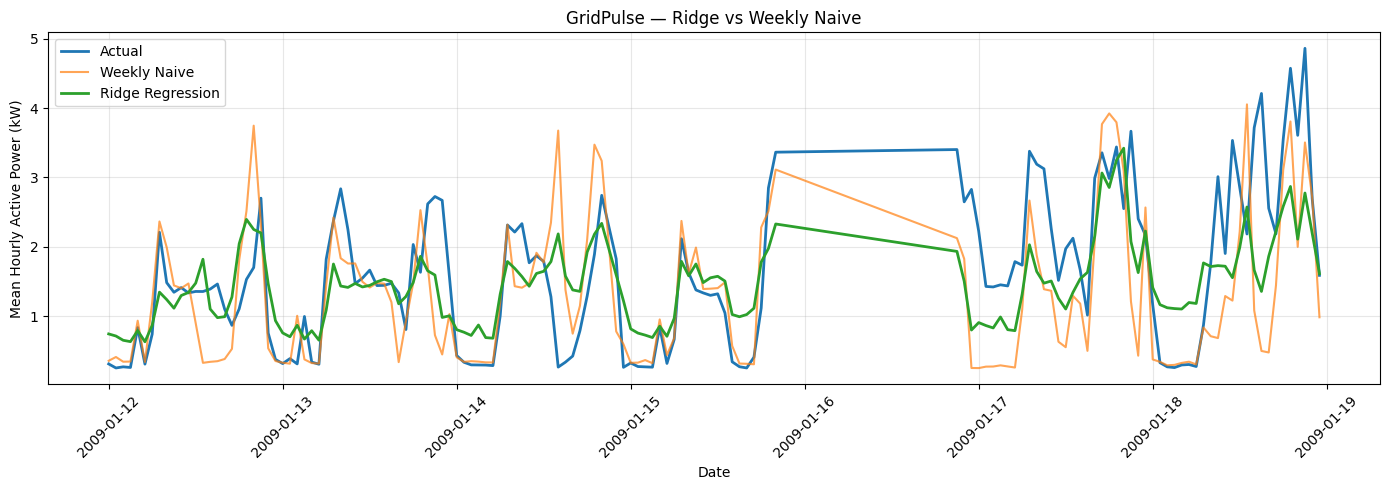

In [21]:
sample = comparison.loc["2009-01-12":"2009-01-18"]

plt.figure(figsize=(14, 5))

plt.plot(sample.index, sample["target_kw"], label="Actual", linewidth=2)

plt.plot(sample.index, sample["lag_168"], label="Weekly Naive", alpha=0.7)

plt.plot(sample.index, sample["ridge"], label="Ridge Regression", linewidth=2)

plt.title("GridPulse — Ridge vs Weekly Naive")
plt.xlabel("Date")
plt.ylabel("Mean Hourly Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Peak Demand Analysis

Investigate how Ridge Regression performs during the
highest electricity demand observations in validation.

In [22]:
peak_comparison = comparison.nlargest(10, "target_kw").copy()

peak_comparison["ridge_error"] = (peak_comparison["target_kw"] - peak_comparison["ridge"])

peak_comparison["weekly_error"] = (peak_comparison["target_kw"] - peak_comparison["lag_168"])

peak_comparison

,target_kw,lag_24,lag_168,ridge,ridge_error,weekly_error
timestamp,,,,,,
2009-02-11 18:00:00,5.233800,1.303867,2.542400,1.829225,3.404575,2.691400
2009-04-12 21:00:00,5.133967,2.738933,1.259500,1.717703,3.416263,3.874467
2009-11-22 20:00:00,5.115167,3.538233,2.040500,2.283798,2.831368,3.074667
2009-04-12 20:00:00,5.098300,4.145133,2.183467,2.365441,2.732859,2.914833
2009-01-24 11:00:00,5.073400,1.592900,1.516567,1.639939,3.433461,3.556833
2009-01-31 17:00:00,5.072500,3.019767,1.065167,2.024522,3.047978,4.007333
2009-01-18 21:00:00,4.860700,3.665800,3.503933,2.775558,2.085142,1.356767
2009-11-03 20:00:00,4.830833,2.753667,2.055633,1.935830,2.895003,2.775200
2009-02-22 17:00:00,4.829433,0.506933,0.357133,1.149596,3.679837,4.472300
